# Time Series Forecasting with Support Vector Regressor
## SVR in the context of time series 
Before understanding the importance of SVR in time series prediction, here are some of the important concepts that you need to know:

- Regression: Supervised learning technique to predict continuous values from a given set of inputs. The idea is to fit a curve (or line) in the feature space that has the maximum number of data points. 

- Support Vector Machine (SVM): A type of supervised machine learning model used for classification, regression and outliers detection. The model is a hyperplane in the feature space, which in case of classification acts as a boundary, and in case of regression acts as the best-fit line. In SVM, a Kernel function is generally used to transform the dataset to a space of higher number of dimensions, so that they can be easily separable. 

- Support Vector Regressor (SVR): A type of SVM, to find the best fit line (which in the case of SVM is a hyperplane) that has the maximum number of data points.

Why SVR? 
In the last lesson you learned about ARIMA, which is a very successful statistical linear method to forecast time series data. However, in many cases, time series data have non-linearity, which cannot be mapped by linear models. In such cases, the ability of SVM to consider non-linearity in the data for regression tasks makes SVR successful in time series forecasting.

## Exercise - build an SVR model

In [71]:
import os
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import datetime as dt
import math

from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import TimeSeriesSplit
from sklearn.svm import SVR
from sklearn.preprocessing import MinMaxScaler
from utils import load_data, mape

energy = load_data('../Data')[['load']]

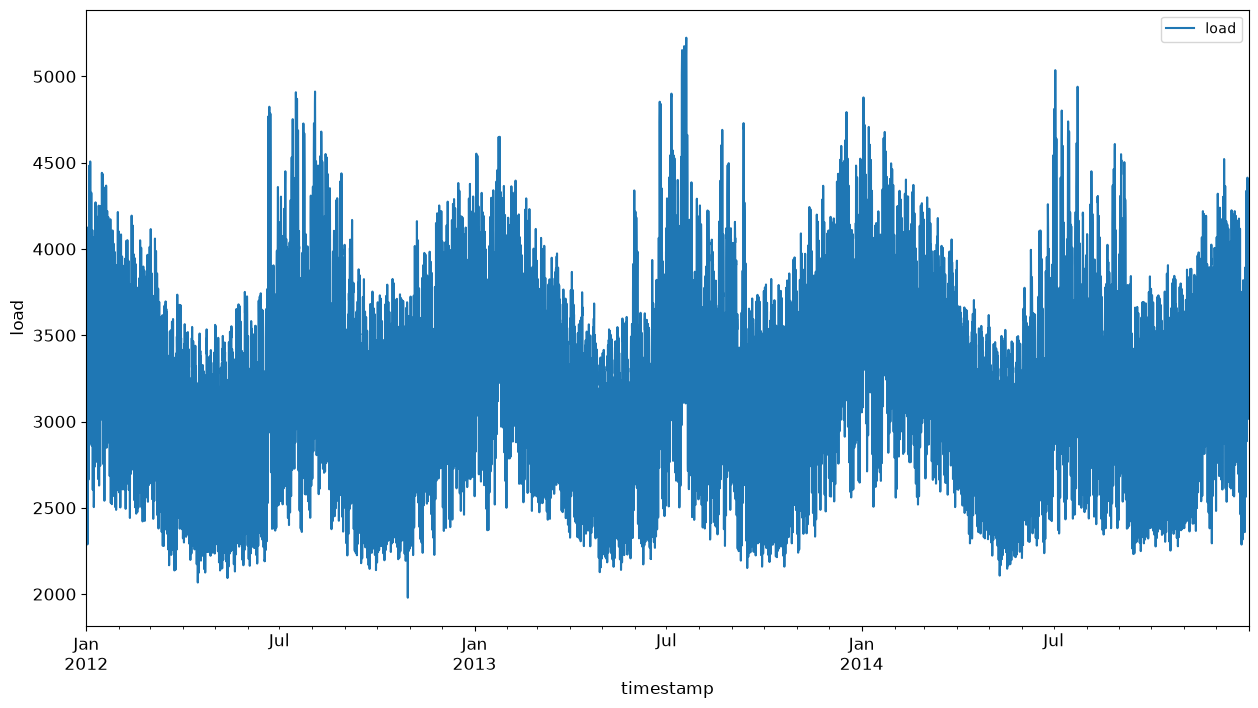

In [72]:
energy.plot(y='load', subplots=True, figsize=(15, 8), fontsize=12)
plt.xlabel('timestamp', fontsize=12)
plt.ylabel('load', fontsize=12)
plt.show()

### Create training and testing datasets

Now your data is loaded, so you can separate it into train and test sets. Then you'll reshape the data to create a time-step based dataset which will be needed for the SVR. You'll train your model on the train set. After the model has finished training, you'll evaluate its accuracy on the training set, testing set and then the full dataset to see the overall performance. You need to ensure that the test set covers a later period in time from the training set to ensure that the model does not gain information from future time periods. (a situation known as Overfitting).

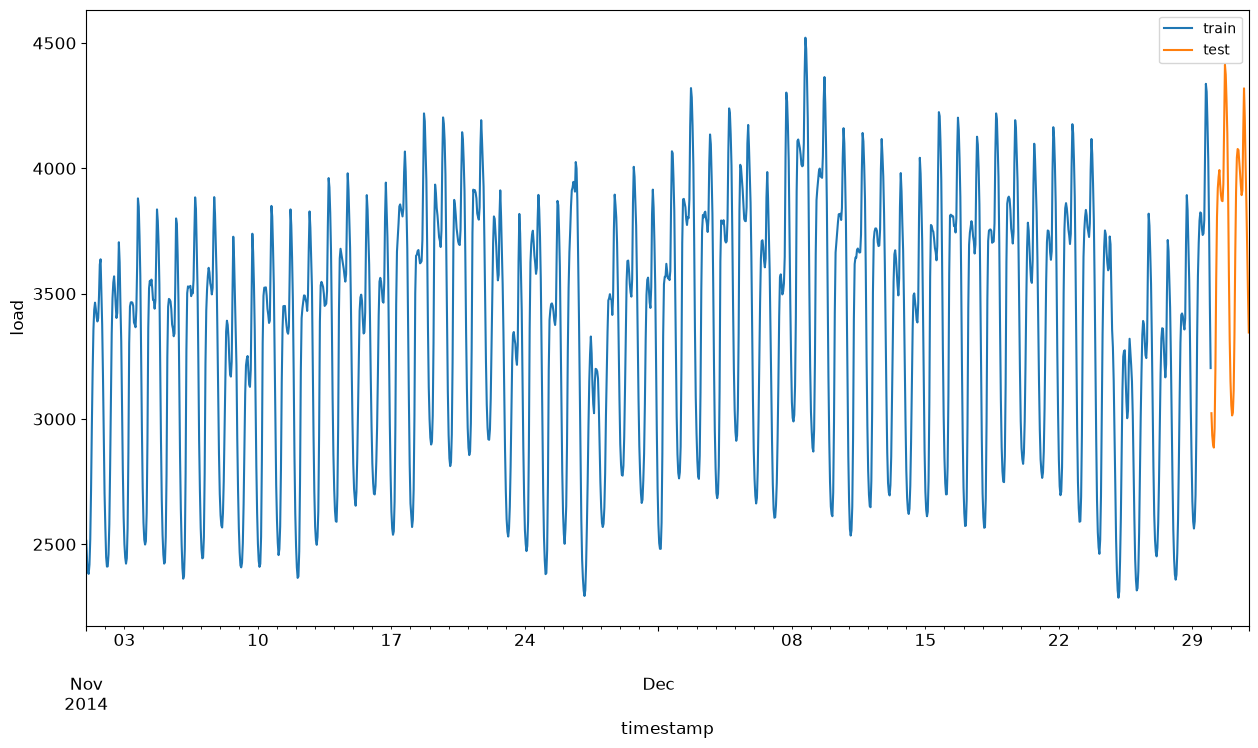

In [73]:
train_start_dt = '2014-11-01 00:00:00'
test_start_dt = '2014-12-30 00:00:00'

energy[(energy.index < test_start_dt) & (energy.index >= train_start_dt)][['load']].rename(columns={'load':'train'}) \
    .join(energy[test_start_dt:][['load']].rename(columns={'load':'test'}), how='outer') \
    .plot(y=['train', 'test'], figsize=(15, 8), fontsize=12)
plt.xlabel('timestamp', fontsize=12)
plt.ylabel('load', fontsize=12)
plt.show()

### Prepare the data for training
Now, you need to prepare the data for training by performing filtering and scaling of your data. Filter your dataset to only include the time periods and columns you need, and scaling to ensure the data is projected in the interval 0,1.

In [74]:
train = energy.copy()[(energy.index >= train_start_dt) & (energy.index < test_start_dt)][['load']]
test = energy.copy()[energy.index >= test_start_dt][['load']]

print('Training data shape: ', train.shape)
print('Test data shape: ', test.shape)

#scaling training data
scaler = MinMaxScaler()
train['load'] = scaler.fit_transform(train)

#scaling testing data
test['load'] = scaler.transform(test)

Training data shape:  (1416, 1)
Test data shape:  (48, 1)


### Create data with time-steps 

For the SVR, you transform the input data to be of the form [batch, timesteps]. So, you reshape the existing train_data and test_data such that there is a new dimension which refers to the timesteps.

In [75]:
# Converting to numpy arrays
train_data = train.values
test_data = test.values

For this example, we take timesteps = 5. So, the inputs to the model are the data for the first 4 timesteps, and the output will be the data for the 5th timestep.


In [76]:
timesteps=5

#Converting training data to 2D tensor using nested list comprehension:
train_data_timesteps=np.array([[j for j in train_data[i:i+timesteps]] for i in range(0,len(train_data)-timesteps+1)])[:,:,0]
train_data_timesteps.shape

#Converting test data to 2D tensor using nested list comprehension:
test_data_timesteps=np.array([[j for j in test_data[i:i+timesteps]] for i in range(0,len(test_data)-timesteps+1)])[:,:,0]
test_data_timesteps.shape

#Selecting inputs and outputs from training and testing data:

x_train, y_train = train_data_timesteps[:,:timesteps-1],train_data_timesteps[:,[timesteps-1]]
x_test, y_test = test_data_timesteps[:,:timesteps-1],test_data_timesteps[:,[timesteps-1]]

print(x_train.shape, y_train.shape)
print(x_test.shape, y_test.shape)


(1412, 4) (1412, 1)
(44, 4) (44, 1)


### Implement SVR 
Now, it's time to implement SVR. For our implementation, we follow these steps:

1. Define the model by calling SVR() and passing in the model hyperparameters: kernel, gamma, c and epsilon

2. Prepare the model for the training data by calling the fit() function
Make predictions calling the predict() function

Now we create an SVR model. Here we use the RBF kernel, and set the hyperparameters gamma, C and epsilon as 0.5, 10 and 0.05 respectively.

## Extra: GridSearchCV

GridSearchCV will automatically try many combinations of hyperparameters (C, gamma, epsilon, etc.) and use cross-validation to find the best combination.

Grid object parameters explained:

- estimator : the model you're tuning.

- param_grid : the combinations to test.

- cv=5 : perform 5-fold cross-validation.

- scoring='neg_mean_squared_error' : optimize for the lowest MSE (scikit-learn uses the negative value because higher scores are considered better).

- n_jobs=-1 : use all available CPU cores.

GridSearchCV already refits the best model on the entire training set by default (refit=True).

You don't need to call .fit() again on best_model because it has already been trained on the full training data.


In [77]:
useGrid = True
model = ""
if not useGrid:
    model = SVR(kernel='rbf',gamma=0.5, C=10, epsilon = 0.05)

    #Fit the model on training data
    model.fit(x_train, y_train[:,0])

    #Make model predictions
    y_train_pred = model.predict(x_train).reshape(-1,1)
    y_test_pred = model.predict(x_test).reshape(-1,1)

    print(y_train_pred.shape, y_test_pred.shape)
else:
    # Base model
    model = SVR(kernel='rbf')

    # Hyperparameter grid
    param_grid = {
        'C': [0.1, 1, 10, 100],
        'gamma': [0.001, 0.01, 0.1, 1],
        'epsilon': [0.01, 0.05, 0.1]
    }

    # Grid search
    grid = GridSearchCV(
        estimator=model,
        param_grid=param_grid,
        cv=TimeSeriesSplit(n_splits=5),
        scoring='neg_mean_squared_error',
        n_jobs=-1
    )

    # Find the best parameters
    grid.fit(x_train, y_train[:, 0])

    print("Best parameters:", grid.best_params_)

    # Best trained model
    best_model = grid.best_estimator_

    # Predictions
    y_train_pred = best_model.predict(x_train).reshape(-1, 1)
    y_test_pred = best_model.predict(x_test).reshape(-1, 1)
    print(y_train_pred.shape, y_test_pred.shape)


Best parameters: {'C': 100, 'epsilon': 0.01, 'gamma': 1}
(1412, 1) (44, 1)


### A note for time series data

If your data is a time series (for example, forecasting energy load), you should avoid the default cv=5, because it randomly splits the data into folds, which can leak future information into the training set.

Instead, use "TimeSeriesSplit(n_splits=5)"

### Evaluate your model 

For evaluation, first we will scale back the data to our original scale. Then, to check the performance, we will plot the original and predicted time series plot, and also print the MAPE result.

In [78]:
# Scaling the predictions
y_train_pred = scaler.inverse_transform(y_train_pred)
y_test_pred = scaler.inverse_transform(y_test_pred)

print(len(y_train_pred), len(y_test_pred))

# Scaling the original values
y_train = scaler.inverse_transform(y_train)
y_test = scaler.inverse_transform(y_test)

print(len(y_train), len(y_test))

1412 44
1412 44


### Check model performance on training and testing data 

We extract the timestamps from the dataset to show in the x-axis of our plot. Note that we are using the first timesteps-1 values as out input for the first output, so the timestamps for the output will start after that.

1412 44


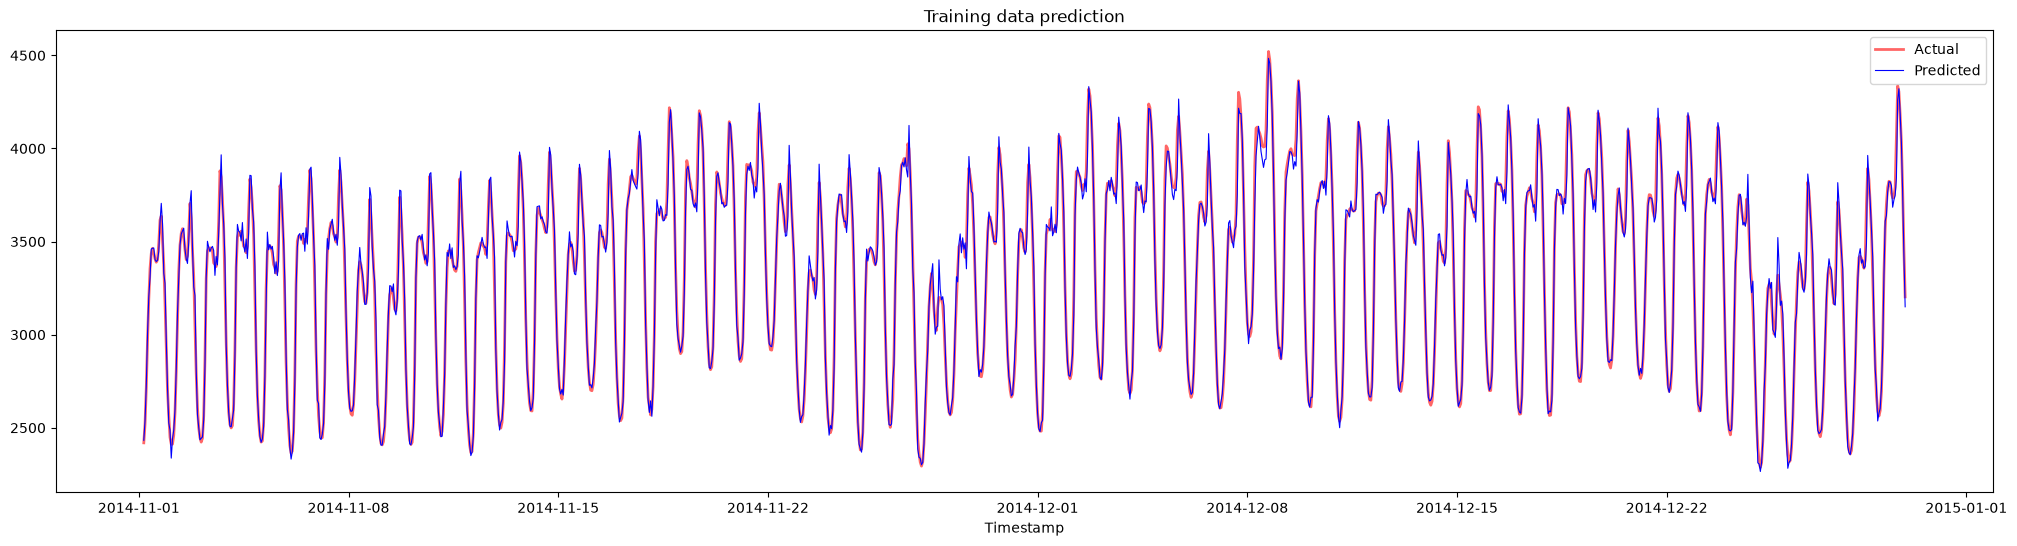

MAPE for training data:  1.0822107912852579 %


In [79]:
train_timestamps = energy[(energy.index < test_start_dt) & (energy.index >= train_start_dt)].index[timesteps-1:]
test_timestamps = energy[test_start_dt:].index[timesteps-1:]

print(len(train_timestamps), len(test_timestamps))

#Plot the predictions for training data:
plt.figure(figsize=(25,6))
plt.plot(train_timestamps, y_train, color = 'red', linewidth=2.0, alpha = 0.6)
plt.plot(train_timestamps, y_train_pred, color = 'blue', linewidth=0.8)
plt.legend(['Actual','Predicted'])
plt.xlabel('Timestamp')
plt.title("Training data prediction")
plt.show()

#Print MAPE for training data
print('MAPE for training data: ', mape(y_train_pred, y_train)*100, '%')



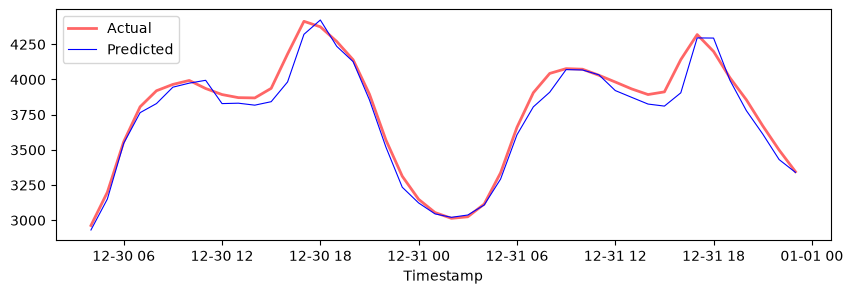

MAPE for testing data:  1.4101951409914277 %


In [80]:
# Repeat for testing data
plt.figure(figsize=(10,3))
plt.plot(test_timestamps, y_test, color = 'red', linewidth=2.0, alpha = 0.6)
plt.plot(test_timestamps, y_test_pred, color = 'blue', linewidth=0.8)
plt.legend(['Actual','Predicted'])
plt.xlabel('Timestamp')
plt.show()

print('MAPE for testing data: ', mape(y_test_pred, y_test)*100, '%')

Tensor shape:  (26300, 5)
X shape:  (26300, 4) 
Y shape:  (26300, 1)


c:\Users\amara\Documents\Notebooks\ml-env\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(


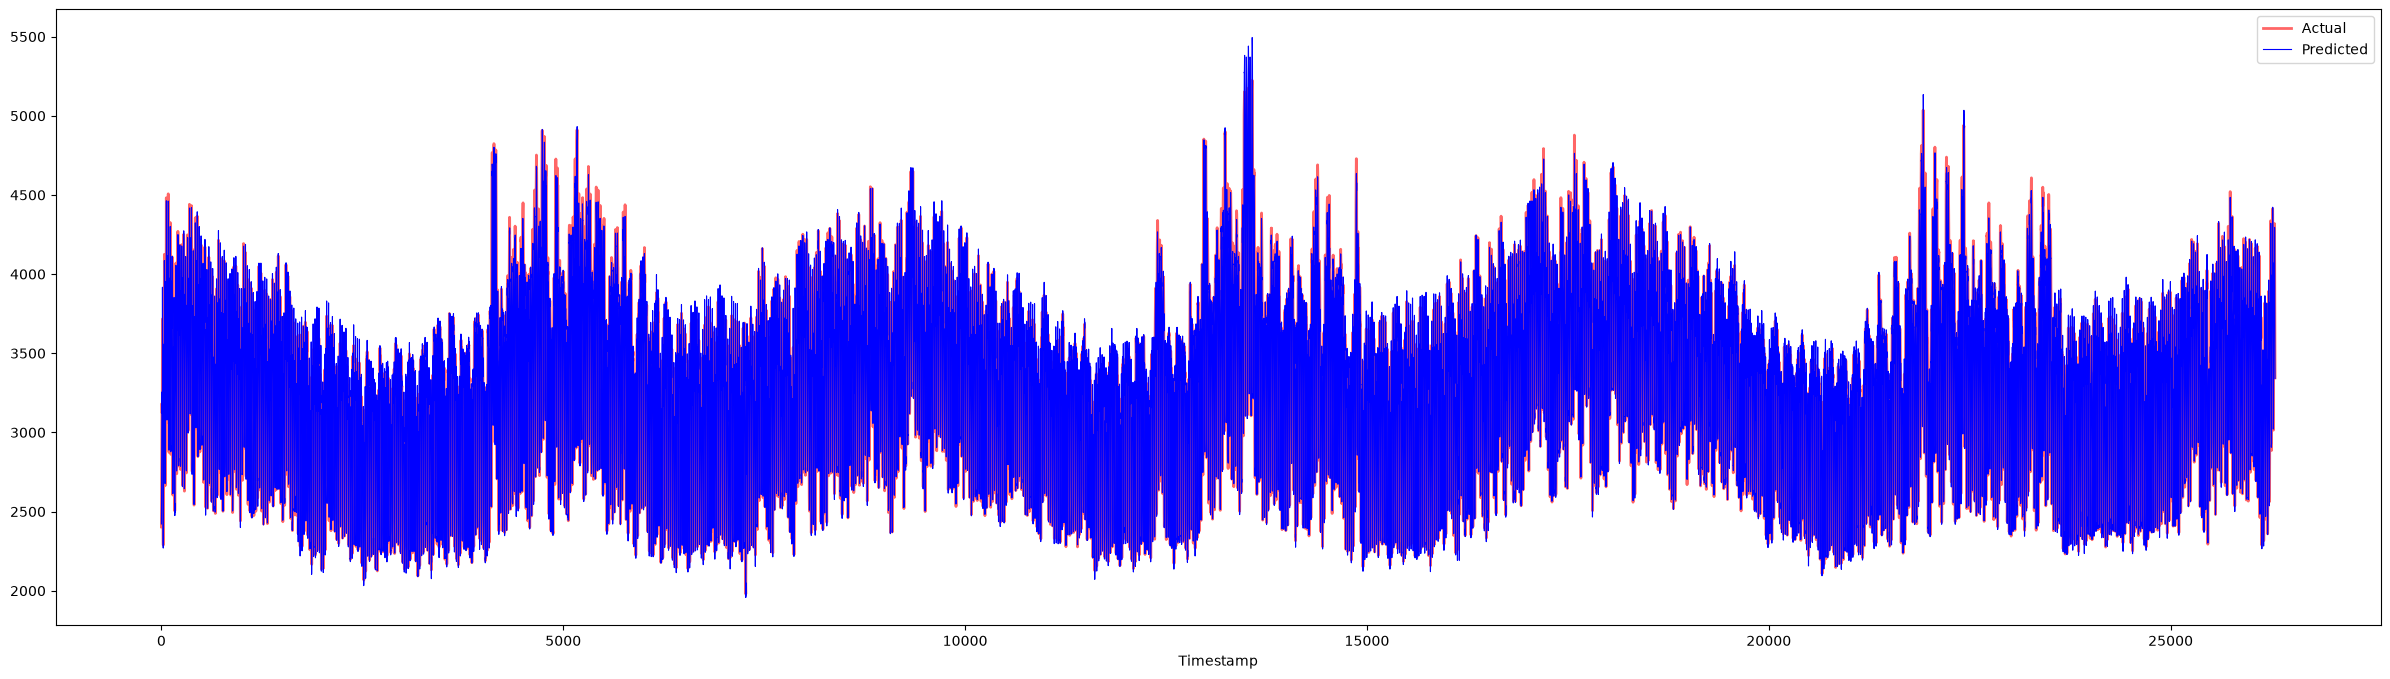

MAPE:  1.3608153757857853 %


In [81]:
#Check model performance on full dataset
# Extracting load values as numpy array
data = energy.copy().values

# Scaling
data = scaler.transform(data)

# Transforming to 2D tensor as per model input requirement
data_timesteps=np.array([[j for j in data[i:i+timesteps]] for i in range(0,len(data)-timesteps+1)])[:,:,0]
print("Tensor shape: ", data_timesteps.shape)

# Selecting inputs and outputs from data
X, Y = data_timesteps[:,:timesteps-1],data_timesteps[:,[timesteps-1]]
print("X shape: ", X.shape,"\nY shape: ", Y.shape)


# Make model predictions
if(not useGrid):
    Y_pred = model.predict(X).reshape(-1,1)
else:
    Y_pred = best_model.predict(X).reshape(-1,1)


# Inverse scale and reshape
Y_pred = scaler.inverse_transform(Y_pred)
Y = scaler.inverse_transform(Y)

plt.figure(figsize=(30,8))
plt.plot(Y, color = 'red', linewidth=2.0, alpha = 0.6)
plt.plot(Y_pred, color = 'blue', linewidth=0.8)
plt.legend(['Actual','Predicted'])
plt.xlabel('Timestamp')
plt.show()

print('MAPE: ', mape(Y_pred, Y)*100, '%')

## Parameters of the RBF Kernel

When training an SVM with the Radial Basis Function (RBF) kernel, two parameters must be considered: C and gamma. The parameter C, common to all SVM kernels, trades off misclassification of training examples against simplicity of the decision surface. A low C makes the decision surface smooth, while a high C aims at classifying all training examples correctly. gamma defines how much influence a single training example has. The larger gamma is, the closer other examples must be to be affected.

Proper choice of C and gamma is critical to the SVM’s performance. One is advised to use GridSearchCV with C and gamma spaced exponentially far apart to choose good values.